In [17]:
import os
import pandas as pd
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from tqdm import tqdm

In [18]:
# 1. Define Paths 
csv_path = '/kaggle/input/datasets/mmoreaux/environmental-sound-classification-50/esc50.csv'
audio_dir = '/kaggle/input/datasets/mmoreaux/environmental-sound-classification-50/audio/audio'

In [19]:
# 2. Load and Filter Metadata
df = pd.read_csv(csv_path)

# Suspicious (Positive = 1): 25 (Footsteps), 39 (Glass breaking), 30 (Door knock), 33 (Door creak)
# Background (Negative = 0): 16 (Wind), 10 (Rain), 19 (Thunderstorm), 44 (Engine), 43 (Car horn), 0 (Dog), 13 (Crickets)
positive_classes = [25, 39, 30, 33]
negative_classes = [16, 10, 19, 44, 43, 0, 13]
target_classes = positive_classes + negative_classes

# Filter the dataset to only include our chosen classes
df_filtered = df[df['target'].isin(target_classes)].copy()

# Map to binary labels
df_filtered['label'] = df_filtered['target'].apply(lambda x: 1 if x in positive_classes else 0)

print(f"Total processed clips: {len(df_filtered)}")
print(f"Positive (Suspicious) count: {len(df_filtered[df_filtered['label'] == 1])}")
print(f"Negative (Background) count: {len(df_filtered[df_filtered['label'] == 0])}")

Total processed clips: 440
Positive (Suspicious) count: 160
Negative (Background) count: 280


In [20]:
# 3. Define Feature Extraction Engine
def extract_features(file_path, target_sr=16000, duration=1.0):
    # Load audio, automatically downsampling to 16 kHz
    y, sr = librosa.load(file_path, sr=target_sr)
    
    # Extract the highest energy 1-second chunk to simulate real-time processing
    chunk_length = int(target_sr * duration)
    if len(y) > chunk_length:
        energy = np.array([sum(abs(y[i:i+chunk_length]**2)) for i in range(0, len(y)-chunk_length, target_sr//2)])
        best_start = (np.argmax(energy) * target_sr) // 2
        y = y[best_start:best_start+chunk_length]
    else:
        # Pad with zeros if shorter than 1 second (rare for ESC-50, but good practice)
        y = np.pad(y, (0, max(0, chunk_length - len(y))), 'constant')
        
    # Generate Mel Spectrogram (64 Mel bands)
    mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64, fmax=8000)
    
    # Convert to Log-Mel (Decibel scale)
    log_mel = librosa.power_to_db(mel_spec, ref=np.max)
    
    # Normalize between 0 and 1
    log_mel_normalized = (log_mel - log_mel.min()) / (log_mel.max() - log_mel.min())
    
    return log_mel_normalized

In [21]:
# 4. Process the Entire Filtered Dataset
X = []
y_labels = []

print("Extracting Log-Mel Spectrograms...")
for index, row in tqdm(df_filtered.iterrows(), total=df_filtered.shape[0]):
    file_name = os.path.join(audio_dir, row['filename'])
    feature = extract_features(file_name)
    
    # CNNs expect a channel dimension, so we reshape from (64, 32) to (64, 32, 1)
    feature = feature[..., np.newaxis] 
    
    X.append(feature)
    y_labels.append(row['label'])

# Convert lists to numpy arrays for TensorFlow/Keras
X = np.array(X)
y_labels = np.array(y_labels)

print(f"\nFeature matrix X shape: {X.shape}")
print(f"Labels matrix Y shape: {y_labels.shape}")

Extracting Log-Mel Spectrograms...


100%|██████████| 440/440 [00:16<00:00, 27.26it/s]


Feature matrix X shape: (440, 64, 32, 1)
Labels matrix Y shape: (440,)


In [22]:
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [23]:
# 1. Split into Training and Validation Sets (80% / 20%)
# Stratify ensures both sets have the same ratio of suspicious vs background sounds
X_train, X_test, y_train, y_test = train_test_split(
    X, y_labels, test_size=0.2, random_state=42, stratify=y_labels
)

In [24]:
# 2. Architect the Lightweight CNN
model = models.Sequential([
    # Block 1: Initial Feature Extraction
    layers.Conv2D(16, (3, 3), activation='relu', input_shape=(64, 32, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.BatchNormalization(),
    
    # Block 2: Complex Pattern Recognition
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.BatchNormalization(),
    
    # Decision Layers
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5), # Prevents overfitting on our small 440-clip dataset
    layers.Dense(1, activation='sigmoid') # Binary output: 1 (Suspicious) or 0 (Background)
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [25]:
# 3. Compile the Model
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

print(model.summary())

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 62, 30, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 31, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 31, 15, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 29, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 6, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 14, 6, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 2688)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       172,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177,153 (692.00 KB)

 Trainable params: 177,057 (691.63 KB)

 Non-trainable params: 96 (384.00 B)

None


In [26]:
# 4. Train the Model
print("\nStarting Training...")
history = model.fit(
    X_train, y_train,
    epochs=25,
    batch_size=16,
    validation_data=(X_test, y_test)
)


Starting Training...
Epoch 1/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.6648 - loss: 0.8758 - val_accuracy: 0.6818 - val_loss: 0.6682
Epoch 2/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8153 - loss: 0.5379 - val_accuracy: 0.6591 - val_loss: 0.6107
Epoch 3/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8580 - loss: 0.3436 - val_accuracy: 0.6364 - val_loss: 0.6617
Epoch 4/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9006 - loss: 0.2385 - val_accuracy: 0.6364 - val_loss: 0.7191
Epoch 5/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9290 - loss: 0.1976 - val_accuracy: 0.6364 - val_loss: 0.7759
Epoch 6/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9062 - loss: 0.2162 - val_accuracy: 0.6364 - val_loss: 0.7487
Epoch 7/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9460 - loss: 0.1715 - val_accuracy: 0.6364 - val_loss: 1.0220
Epoch 8/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9432 - loss: 0.1649 - val_accur

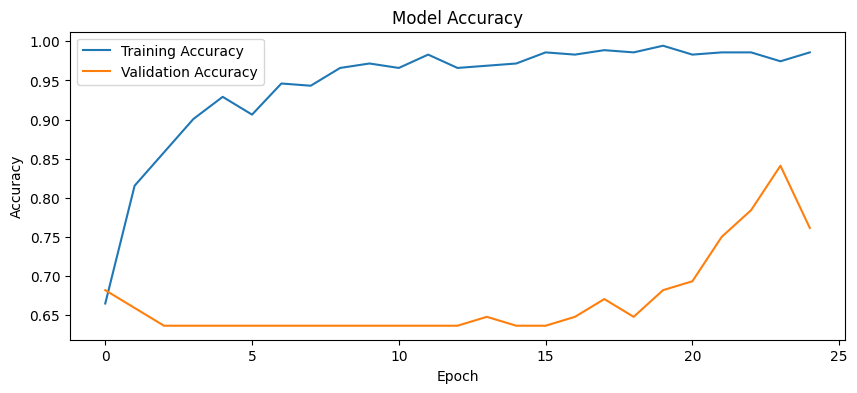

In [27]:
# 5. Plot Training History
plt.figure(figsize=(10, 4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 239ms/step


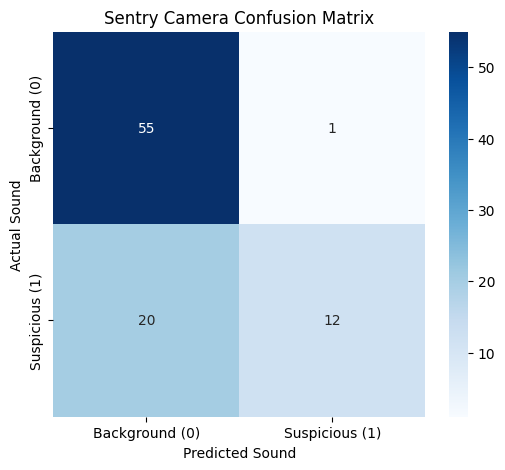


Classification Report:
                precision    recall  f1-score   support

Background (0)       0.73      0.98      0.84        56
Suspicious (1)       0.92      0.38      0.53        32

      accuracy                           0.76        88
     macro avg       0.83      0.68      0.69        88
  weighted avg       0.80      0.76      0.73        88



In [28]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# 1. Generate probability predictions on the unseen 20% test set
y_pred_probs = model.predict(X_test)

# 2. Convert sigmoid probabilities to binary class labels (Threshold = 0.5)
y_pred_classes = (y_pred_probs >= 0.5).astype(int)

# 3. Compute the raw Confusion Matrix
cm = confusion_matrix(y_test, y_pred_classes)

# 4. Visualize the Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Background (0)', 'Suspicious (1)'], 
            yticklabels=['Background (0)', 'Suspicious (1)'])
plt.ylabel('Actual Sound')
plt.xlabel('Predicted Sound')
plt.title('Sentry Camera Confusion Matrix')
plt.show()

# 5. Print the Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_classes, target_names=['Background (0)', 'Suspicious (1)']))

In [29]:
# Test a lower detection threshold (e.g., 0.3 instead of 0.5)
custom_threshold = 0.30
y_pred_tuned = (y_pred_probs >= custom_threshold).astype(int)

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
print(f"--- Confusion Matrix at Threshold {custom_threshold} ---")
print(cm_tuned)
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_tuned, target_names=['Background (0)', 'Suspicious (1)']))

--- Confusion Matrix at Threshold 0.3 ---
[[52  4]
 [15 17]]

--- Classification Report ---
                precision    recall  f1-score   support

Background (0)       0.78      0.93      0.85        56
Suspicious (1)       0.81      0.53      0.64        32

      accuracy                           0.78        88
     macro avg       0.79      0.73      0.74        88
  weighted avg       0.79      0.78      0.77        88



In [30]:
import tensorflow as tf
import tensorflow_hub as hub
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models

# 1. Load the Pre-trained YAMNet Model
print("Loading YAMNet from TensorFlow Hub...")
yamnet_model = hub.load('https://tfhub.dev/google/yamnet/1')

def extract_yamnet_embeddings(file_path, target_sr=16000, duration=1.0):
    # Load raw audio
    y, sr = librosa.load(file_path, sr=target_sr)
    
    # Extract the highest energy 1-second chunk
    chunk_length = int(target_sr * duration)
    if len(y) > chunk_length:
        energy = np.array([sum(abs(y[i:i+chunk_length]**2)) for i in range(0, len(y)-chunk_length, target_sr//2)])
        best_start = (np.argmax(energy) * target_sr) // 2
        y = y[best_start:best_start+chunk_length]
    else:
        y = np.pad(y, (0, max(0, chunk_length - len(y))), 'constant')
        
    # Normalize waveform to [-1.0, 1.0] range required by YAMNet
    if np.max(np.abs(y)) > 0:
        y = y / np.max(np.abs(y))
    
    # Run inference through YAMNet
    # YAMNet returns: class_scores, embeddings, log_mel_spectrogram
    scores, embeddings, spectrogram = yamnet_model(y)
    
    # Average the frame-level embeddings into a single 1024-D vector for the clip
    clip_embedding = tf.reduce_mean(embeddings, axis=0).numpy()
    return clip_embedding

# 2. Extract YAMNet Features for the Dataset
X_yamnet = []
print("Extracting YAMNet Embeddings for all clips...")
for index, row in tqdm(df_filtered.iterrows(), total=df_filtered.shape[0]):
    file_name = os.path.join(audio_dir, row['filename'])
    embedding = extract_yamnet_embeddings(file_name)
    X_yamnet.append(embedding)

X_yamnet = np.array(X_yamnet)
print(f"\nYAMNet Feature matrix X shape: {X_yamnet.shape}")

# 3. Split the Data
X_train_y, X_test_y, y_train_y, y_test_y = train_test_split(
    X_yamnet, y_labels, test_size=0.2, random_state=42, stratify=y_labels
)

# 4. Build a Lightweight Classifier Head
transfer_model = models.Sequential([
    layers.InputLayer(input_shape=(1024,)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid') # Binary decision layer
])

transfer_model.compile(optimizer='adam',
                       loss='binary_crossentropy',
                       metrics=['accuracy'])

print(transfer_model.summary())

# 5. Train the New Classifier
print("\nStarting YAMNet Transfer Learning...")
history_yamnet = transfer_model.fit(
    X_train_y, y_train_y,
    epochs=25,
    batch_size=16,
    validation_data=(X_test_y, y_test_y)
)

/usr/local/lib/python3.12/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Loading YAMNet from TensorFlow Hub...
Extracting YAMNet Embeddings for all clips...


100%|██████████| 440/440 [00:10<00:00, 43.10it/s]


YAMNet Feature matrix X shape: (440, 1024)



/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 262,657 (1.00 MB)

 Trainable params: 262,657 (1.00 MB)

 Non-trainable params: 0 (0.00 B)

None

Starting YAMNet Transfer Learning...
Epoch 1/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.8466 - loss: 0.3526 - val_accuracy: 0.9318 - val_loss: 0.1521
Epoch 2/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9261 - loss: 0.1905 - val_accuracy: 0.9545 - val_loss: 0.1031
Epoch 3/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9574 - loss: 0.1242 - val_accuracy: 0.9659 - val_loss: 0.0804
Epoch 4/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9744 - loss: 0.1014 - val_accuracy: 0.9773 - val_loss: 0.0722
Epoch 5/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9688 - loss: 0.1545 - val_accuracy: 0.9773 - val_loss: 0.0665
Epoch 6/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9744 - loss: 0.0895 - val_accuracy: 0.9773 - val_loss: 0.0636
Epoch 7/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9773 - loss: 0.0862 - val_accuracy: 0.9773 - val_loss: 0.0609
Epoch 8/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9830 - los

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


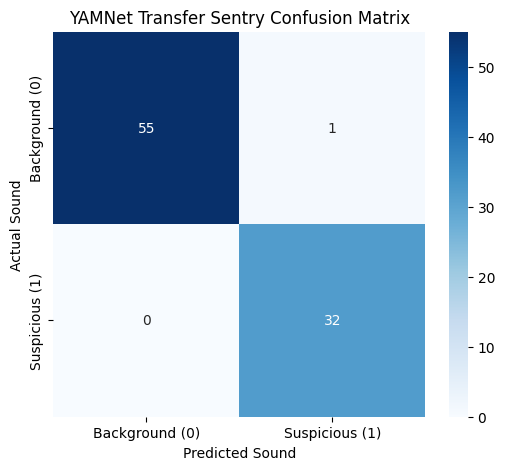


Classification Report (YAMNet Transfer Model):
                precision    recall  f1-score   support

Background (0)       1.00      0.98      0.99        56
Suspicious (1)       0.97      1.00      0.98        32

      accuracy                           0.99        88
     macro avg       0.98      0.99      0.99        88
  weighted avg       0.99      0.99      0.99        88



In [31]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Predict probabilities using the transfer model
y_pred_probs_yamnet = transfer_model.predict(X_test_y)

# 2. Standard 0.5 binary threshold
y_pred_classes_yamnet = (y_pred_probs_yamnet >= 0.5).astype(int)

# 3. Confusion Matrix
cm_yamnet = confusion_matrix(y_test_y, y_pred_classes_yamnet)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_yamnet, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Background (0)', 'Suspicious (1)'], 
            yticklabels=['Background (0)', 'Suspicious (1)'])
plt.ylabel('Actual Sound')
plt.xlabel('Predicted Sound')
plt.title('YAMNet Transfer Sentry Confusion Matrix')
plt.show()

# 4. Classification Report
print("\nClassification Report (YAMNet Transfer Model):")
print(classification_report(y_test_y, y_pred_classes_yamnet, 
                            target_names=['Background (0)', 'Suspicious (1)']))

In [33]:
import tensorflow as tf

# 1. Initialize the TFLite Converter with the trained model
converter = tf.lite.TFLiteConverter.from_keras_model(transfer_model)

# 2. Apply Dynamic Range Quantization (FP32 -> INT8)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# 3. Convert the model
tflite_quant_model = converter.convert()

# 4. Save to disk
export_path = 'sentry_classifier_quantized.tflite'
with open(export_path, 'wb') as f:
    f.write(tflite_quant_model)

print("Quantized TFLite model exported successfully.")
print(f"Final Model Size: {len(tflite_quant_model) / 1024:.2f} KB")

INFO:tensorflow:Assets written to: /tmp/tmppkx1p14m/assets


INFO:tensorflow:Assets written to: /tmp/tmppkx1p14m/assets


Saved artifact at '/tmp/tmppkx1p14m'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1024), dtype=tf.float32, name='keras_tensor_44')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  132544035791952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132540590521616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132540590522192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132540590521040: TensorSpec(shape=(), dtype=tf.resource, name=None)
Quantized TFLite model exported successfully.
Final Model Size: 262.70 KB


W0000 00:00:1789930114.819714      58 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1789930114.819743      58 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


In [35]:
import tensorflow as tf
import tensorflow_hub as hub

# 1. Create a custom wrapper layer to bypass the Keras compatibility issue
class YAMNetFeatureExtractor(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        # Load the raw TensorFlow model instead of using hub.KerasLayer
        self.yamnet = hub.load('https://tfhub.dev/google/yamnet/1')
        
    def call(self, waveform):
        # Keras inputs automatically add a batch dimension (e.g., Shape: (1, audio_samples))
        # YAMNet strictly expects a flat 1D array, so we squeeze the batch dimension out
        waveform_1d = tf.squeeze(waveform, axis=0) 
        
        # Run inference (YAMNet returns: scores, embeddings, spectrogram)
        _, embeddings, _ = self.yamnet(waveform_1d)
        
        # Average the frame-level embeddings into a single clip-level vector
        avg_emb = tf.reduce_mean(embeddings, axis=0)
        
        # Restore the batch dimension so the dense classifier can read it: Shape (1, 1024)
        return tf.expand_dims(avg_emb, axis=0)

# 2. Define the input layer (fixing the batch size to 1 for real-time edge inference)
audio_input = tf.keras.layers.Input(shape=(None,), batch_size=1, dtype=tf.float32, name='raw_audio')

# 3. Wire the custom YAMNet layer directly into your trained classification head
features = YAMNetFeatureExtractor()(audio_input)
classification_output = transfer_model(features)

# 4. Package them together into a single End-to-End model
end_to_end_model = tf.keras.Model(inputs=audio_input, outputs=classification_output)

# 5. Convert to an 8-bit quantized TFLite file
print("Converting to quantized TFLite model...")
converter = tf.lite.TFLiteConverter.from_keras_model(end_to_end_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_e2e_model = converter.convert()

# 6. Export for the Raspberry Pi
export_path = 'sentry_end_to_end_quantized.tflite'
with open(export_path, 'wb') as f:
    f.write(tflite_e2e_model)
    
print("End-to-End model compiled and exported successfully!")
print(f"Final Model Size: {len(tflite_e2e_model) / 1024 / 1024:.2f} MB")

Converting to quantized TFLite model...
INFO:tensorflow:Assets written to: /tmp/tmpgqas68i1/assets


INFO:tensorflow:Assets written to: /tmp/tmpgqas68i1/assets


Saved artifact at '/tmp/tmpgqas68i1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, None), dtype=tf.float32, name='raw_audio')
Output Type:
  TensorSpec(shape=(1, 1), dtype=tf.float32, name=None)
Captures:
  132539148023376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132539148021648: TensorSpec(shape=(32,), dtype=tf.float32, name=None)
  132539148023184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132539148022992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132539148022800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132539148022416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132539148020688: TensorSpec(shape=(32,), dtype=tf.float32, name=None)
  132539148022224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132539148022032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132539148021840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132539148021456: TensorSpe

W0000 00:00:1789930620.229885      58 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1789930620.229938      58 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
